In [1]:
import numpy as np 
inputx=np.array([1.0,2.0,3.0])
expout=np.array([2.0,4.1,5.9])
weight=0.0
learningrate=0.05
for step in range(1,51):
    model=weight*inputx
    #Here model-expout is the loss function that is to know how much the model is wrong in predicting the answer
    #This grad is the differentitation of the mean function and then that is for the calculation of the gradient
    grad=2*np.mean(inputx*(model-expout))
    weight-=learningrate*grad
    if step in (1,2,3,4,20,50):
        print(step, round(weight,4),round(np.mean((model-expout)**2),4))


1 0.93 18.54
2 1.426 5.2782
3 1.6905 1.506
4 1.8316 0.433
20 1.9929 0.0064
50 1.9929 0.0064


# Estimating the price per Kg of produce

In [6]:
import numpy as np
batchweight=np.array([2.0,5.0,10.0])
totalcost=np.array([62.0,148.0,310.0])
weight=0.0
learningrate=0.01
for step in range(1,51):
    model=weight*batchweight
    grad=2*np.mean(batchweight*(model-totalcost))
    weight-=grad*learningrate
    if step in (1,2,3,4,5,20,30,40,50):
        print(step, round(weight,4), round(np.mean((model-totalcost)**2),4))
custweight=int(input("Enter the weight for the model to guess the cost"))
print("The predicted cost by the model is",round((weight*custweight),4))

1 26.4267 40616.0
2 30.1264 808.9835
3 30.6444 28.7659
4 30.7169 13.4737
5 30.727 13.174
20 30.7287 13.168
30 30.7287 13.168
40 30.7287 13.168
50 30.7287 13.168
The predicted cost by the model is 1536.4341


## Estimating Electric Vehicle charging speed

In [ ]:
import numpy as np
chargingtime=np.array([0.5,1.5,3.0])
Energyadded=np.array([24.0,76.0,148.0])
weight=0
learningrate=0.1
for step in range(1,51):
    model=weight*chargingtime
    grad=2*np.mean(chargingtime*(model-Energyadded))
    weight-=grad*learningrate
    if step in (1,2,3,20,50):
        print(f"STEP {step} || WEIGHT {round(weight,4)} || LOSSVALUE {round(np.mean((model-Energyadded)**2),4)}")
custchartime=float(input("Enter the charging time for the model to predict what is the value of the energy gained"))
print("The model is predicting...")
print("The value of energyadded predicted by the model",round(weight*custchartime ,4))

STEP 1 || WEIGHT 38.0 || LOSSVALUE 9418.6667
STEP 2 || WEIGHT 46.8667 || LOSSVALUE 514.0
STEP 3 || WEIGHT 48.9356 || LOSSVALUE 29.1904
STEP 20 || WEIGHT 49.5652 || LOSSVALUE 1.2754
STEP 50 || WEIGHT 49.5652 || LOSSVALUE 1.2754
The model is predicting...
The value of energyadded predicted by the model 793.0435


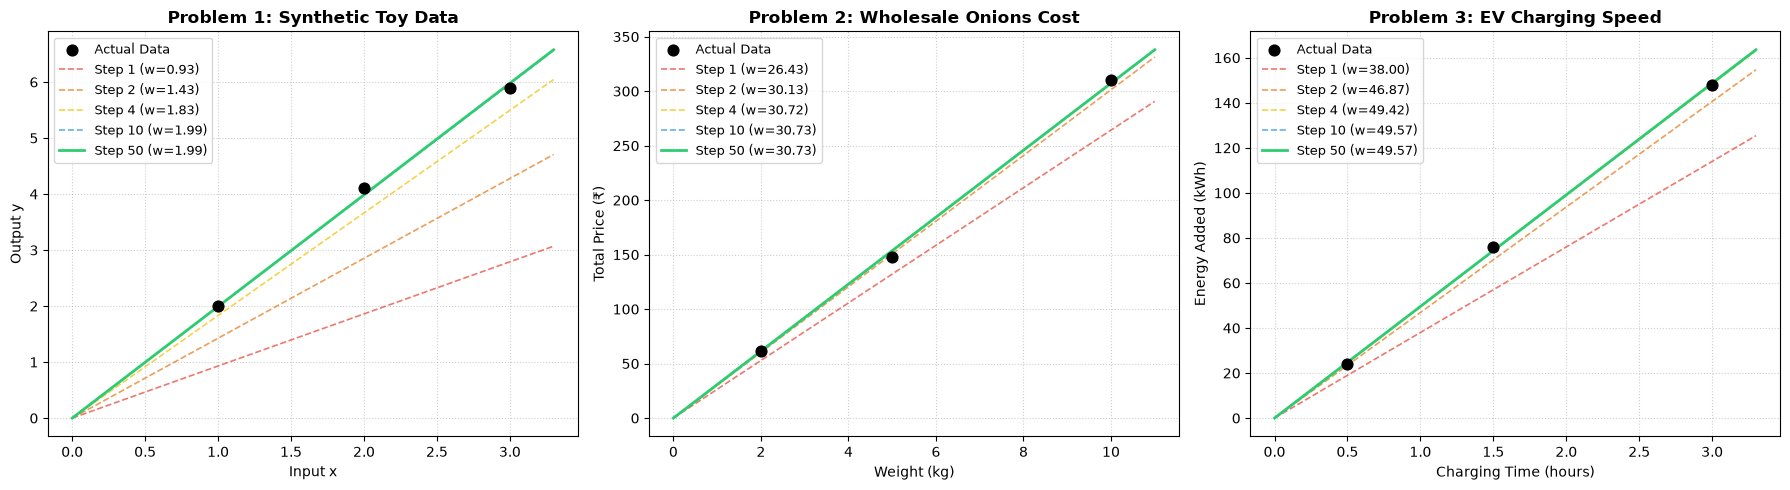

In [11]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 1. Datasets and configurations from your 3 problems
# ---------------------------------------------------------
problems = [
    {
        "title": "Problem 1: Synthetic Toy Data",
        "x": np.array([1.0, 2.0, 3.0]),
        "y": np.array([2.0, 4.1, 5.9]),
        "lr": 0.05,
        "xlabel": "Input x",
        "ylabel": "Output y"
    },
    {
        "title": "Problem 2: Wholesale Onions Cost",
        "x": np.array([2.0, 5.0, 10.0]),
        "y": np.array([62.0, 148.0, 310.0]),
        "lr": 0.01,
        "xlabel": "Weight (kg)",
        "ylabel": "Total Price (₹)"
    },
    {
        "title": "Problem 3: EV Charging Speed",
        "x": np.array([0.5, 1.5, 3.0]),
        "y": np.array([24.0, 76.0, 148.0]),
        "lr": 0.1,
        "xlabel": "Charging Time (hours)",
        "ylabel": "Energy Added (kWh)"
    }
]

# Steps we want to capture and plot
snapshot_steps = [1, 2, 4, 10, 50]
colors = ['#e74c3c', '#e67e22', '#f1c40f', '#3498db', '#2ecc71']

# ---------------------------------------------------------
# 2. Plotting loop
# ---------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, p in enumerate(problems):
    ax = axes[idx]
    x, y, lr = p["x"], p["y"], p["lr"]
    weight = 0.0
    
    # Line domain for drawing continuous prediction lines
    x_line = np.linspace(0, np.max(x) * 1.1, 100)
    
    # Scatter actual training data points
    ax.scatter(x, y, color='black', s=60, zorder=5, label='Actual Data')
    
    color_idx = 0
    for step in range(1, 51):
        model = weight * x
        grad = 2 * np.mean(x * (model - y))
        weight -= lr * grad
        
        # Draw the regression line at chosen milestones
        if step in snapshot_steps:
            y_line = weight * x_line
            ax.plot(
                x_line, 
                y_line, 
                label=f'Step {step} (w={weight:.2f})', 
                color=colors[color_idx], 
                linewidth=2 if step == 50 else 1.2,
                linestyle='-' if step == 50 else '--',
                alpha=1.0 if step == 50 else 0.75
            )
            color_idx += 1
            
    ax.set_title(p["title"], fontsize=12, fontweight='bold')
    ax.set_xlabel(p["xlabel"])
    ax.set_ylabel(p["ylabel"])
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.legend(fontsize=9)

plt.tight_layout()
plt.show()